# 2. EDA Visualization

## Summary

**What this notebook covers:** exploratory analysis of the cleaned works table (5,949,217 works, 1,034,756 artists). It looks at how works spread across years, artists, genres and styles, how much year data is missing and why, whether the WHAT target (a work introducing a style the artist never used before) has a usable base rate, six hypothesis tests (five on what drives that target, one on the WHEN timing signal), and a check of transformations and correlations for the count variables (section 8).

**Key findings**

- **Year cleaning:** `year == 0` and years after 2026 are treated as missing, and a Master's missing year is recovered from its earliest Release (38.1% of the masters missing a year at that step; 37,354 filled and 61,388 still missing in the final table). 8.58% of works still have no year (3.1% of masters, 11.2% of synthetic works).
- **Missing-year handling:** missing year is not random. It runs from 25.7% (Latin) to 1.5% (Electronic) by genre and mostly tracks catalog age. Decision: keep these works and artists, add a `year_missing` flag, and use a model that handles missing values natively.
- **WHAT base rate:** 18.1% of transitions (3+ prior works) introduce a new style, stable across cutoffs of 2, 3 and 5, so the target is learnable.
- **H1, does the new-style rate change with prior-work count?** H0 rejected. The rate falls from 26.9% (3-5 works) to 6.2% (51+), so prior-work count is a strong feature.
- **H2, does genre matter once prior-work count is held fixed?** H0 rejected in all five buckets. Genre matters (Cramer's V 0.155 down to 0.062), but its effect shrinks as history grows.
- **H3, do longer gaps between works go with more new styles?** H0 rejected. The rate rises from 13.9% at 0 years to 28.3% at 11+, but the effect is small (rank-biserial 0.169).
- **H4, do artists with more prior styles add new ones more or less often?** H0 rejected. Pooled the pattern is muddy, but inside each work bucket more prior styles means a higher chance of another new one.
- **H5, does `year_missing` change the new-style rate?** H0 rejected (14.6% vs 20.0%), but most of the gap is catalog length. With prior-work count held fixed it nearly disappears, which supports keeping these artists.
- **H6, does the chance of releasing next year depend on years since the last release?** H0 rejected. The rate falls from 54.8% (1 year) to 12.5% (10+), Cramer's V 0.313, and the effect holds inside every history bucket (V 0.244 to 0.356).
- **Transformations and correlations (section 8):** `log1p` cuts the skewness of the three count columns (7.34 to 0.92 for `prior_work_count`, 7.77 to 1.52 for `year_gap`, 3.35 to 0.15 for `prior_style_count`) but normality is still rejected on a 5,000-row sample, so rank-based tests are kept. The six Spearman correlations are all significant at n = 3,254,604, so the size of r is what matters (strongest: `prior_work_count` with `prior_style_count`, 0.589). No transformation is added to the pipeline.
- **Caveats:** recovery does not close the missing-year gap across genres, and years from 2024 on are undercounted by the load delay of the dump, and 2026 is a partial year.

**Next:** these findings feed into feature engineering (prior-work count, year gap, prior style count, genre, `year_missing`) and the train/test split.

## 0. Data Loading

In [1]:
import sys  # needed to extend the module search path
sys.path.append('../src')  # make src/ importable from inside notebooks/

import pandas as pd  # dataframe library used throughout the notebook

works_df = pd.read_parquet('../data/processed/works_checkpoint.parquet')  # load the cleaned, finalized works table
works_df.shape  # confirm row and column counts after loading

(5949217, 9)

## 1. Univariate

### Question: How is `year` distributed across works_df, and does the missing-year share concentrate in any particular era?

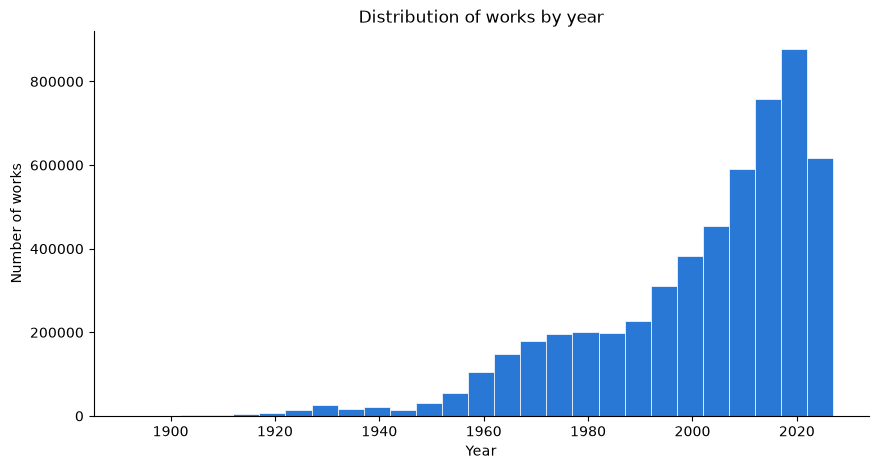

{'missing_count': 510364, 'missing_share': 0.08578675143300371}

In [2]:
from eda import plot_year_distribution  # reusable plotting function lives in src/eda.py

year_stats = plot_year_distribution(works_df)  # draw the histogram and capture missing-year numbers
year_stats  # print the missing-year count and share

In [3]:
from eda import missing_year_by_source  # reusable summary function lives in src/eda.py

missing_year_by_source(works_df)  # missing-year count and share split by work_source

,total,missing,missing_share
work_source,,,
master,1951057,61388,0.031464
synthetic,3998160,448976,0.112296


### Interpretation

`year` is heavily right-skewed: volume is low and flat before 1960, grows through the 2000s, and peaks around 2020. The drop after 2020 is most likely a dump-cutoff effect, not a real decline. Missing year cannot sit on a histogram, but it concentrates by `work_source`: 3.1% of masters (61,388 of 1,951,057) versus 11.2% of synthetic works (448,976 of 3,998,160), 8.58% overall.

### Decision

No cleaning here (EDA stage). The missing-year strategy in `docs/decisions.md` must account for synthetic works being about 3.5x more likely to lack a year than masters.

### Question: How many works does each artist have, and are there any anomalous/outlier artists by volume?

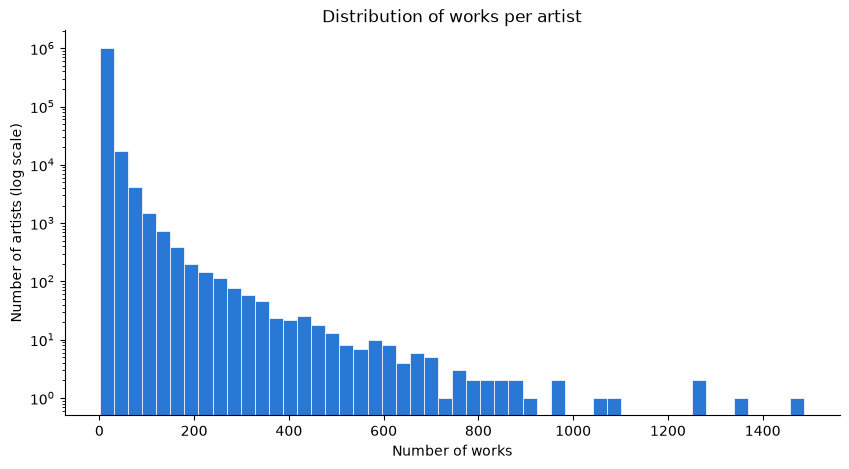

count    1.034756e+06
mean     5.749299e+00
std      1.377021e+01
min      1.000000e+00
50%      3.000000e+00
75%      6.000000e+00
90%      1.200000e+01
95%      1.900000e+01
99%      5.100000e+01
max      1.488000e+03
dtype: float64

In [4]:
from eda import plot_works_per_artist  # reusable plotting/summary function lives in src/eda.py

works_per_artist_stats, top_artists = plot_works_per_artist(works_df)  # draw the histogram, capture stats and the top-N table
works_per_artist_stats  # mean, median, percentiles, max of works per artist

In [5]:
top_artists  # top 15 artists by work count, checked by hand for remaining outliers

,artist,work_count
artist_id,,
164571.0,Bing Crosby,1488
27518.0,Elvis Presley,1340
52833.0,Frank Sinatra,1265
181485.0,Eugene Chadbourne,1258
6351861.0,This Is What I Hear When You Talk,1091
4607669.0,Merzlux,1052
2775248.0,Claudio Giordano,963
106892.0,Sizzla,963
781235.0,Claudio Villa,922


In [6]:
top_artist_id = top_artists.index[0]  # current #1 artist by work count
top_artist_sample = works_df[works_df["artist_id"] == top_artist_id]
top_artist_sample[["work_id", "title", "year", "work_source"]].sample(15, random_state=1)  # eyeball a random sample of its titles

,work_id,title,year,work_source
702960,2169970,As Long As I Am Dreaming / Smile Right Back At...,1947.0,master
703972,10016304374,Stardust / Concentratin',NaN,synthetic
703778,10008015032,One Night Stand With Bing Crosby At The Music ...,NaN,synthetic
703552,974657,Just One More Chance / Star Dust,1936.0,master
703430,1324282,I Love To Dance Like They Used To Dance,1975.0,master
704208,10032198568,Vol. II,NaN,synthetic
704347,1673330,You're The Moment Of A Lifetime / No Te Import...,1941.0,master
703917,10010883923,"Sing, Sing, Sing = Zing A Little Song / Das Mä...",NaN,synthetic
703754,10015009929,Ol' Man River / Swanee River,NaN,synthetic
704167,956357,Tobermory Bay,1954.0,master


### Interpretation

Works per artist is heavily right-skewed: median 3, mean 5.7, 90th percentile 12, 99th percentile 51, max 1,488 (log scale needed on the y-axis). The top 15 are all plausible: legacy artists with decades of reissues (Bing Crosby, Elvis Presley, Frank Sinatra), prolific reggae artists, and a few high-output underground projects. A sample of the top artist's titles (Bing Crosby) showed real single and album releases, not an upload pattern. "Nosferatu 1922", flagged in an earlier run, no longer appears because the mass-upload exclusion already removed it.

### Decision

No filtering here. The new top of the distribution is legitimate, so the upstream exclusion worked as intended.

### Question: How much would extreme-volume artists distort future snapshot generation?

In [7]:
from eda import artist_volume_concentration  # reusable summary function lives in src/eda.py

artist_volume_concentration(works_df)  # top 1% vs bottom 50% (works) and top 1% vs median artist (potential snapshots)

{'n_artists': 1034756,
 'top_1pct_n_artists': 10348,
 'top_1pct_work_share': 0.17156716570949462,
 'bottom_50pct_work_share': 0.1264801764025011,
 'top_1pct_snapshot_share': 0.2055862343179161,
 'median_artist_snapshots': 2.0,
 'median_artist_snapshot_share': 4.069700954304177e-07}

### Interpretation

The top 1% of artists (10,348 of 1,034,756) hold 17.2% of all works and 20.6% of all potential snapshots, while the bottom 50% hold only 12.6% of works combined. A median artist contributes a negligible share of snapshots on their own. So even without the removed mass-upload artist, a few legitimate high-volume artists would dominate a snapshot dataset built without a cap or weighting.

### Decision

No cap or weighting applied yet (`snapshots.py` is not built). Logged as a PENDING item in `docs/decisions.md`.

## 2. Bivariate

### Question: How does total work volume trend over time, and which genres/styles dominate works_df overall?

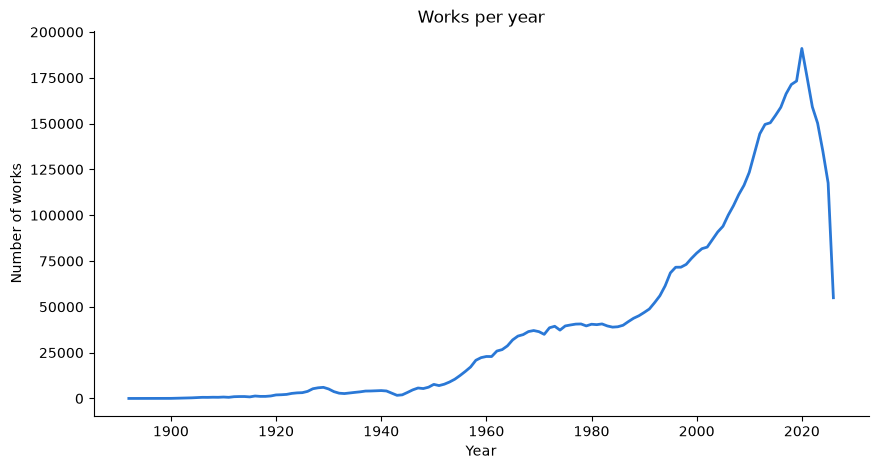

year
2022.0    159118
2023.0    150212
2024.0    134900
2025.0    117600
2026.0     54958
Name: count, dtype: int64

In [8]:
from eda import plot_works_per_year  # reusable plotting function lives in src/eda.py

works_per_year = plot_works_per_year(works_df)  # draw the time series, capture per-year counts
works_per_year.tail()  # most recent years, to check the post-2020 drop-off seen earlier

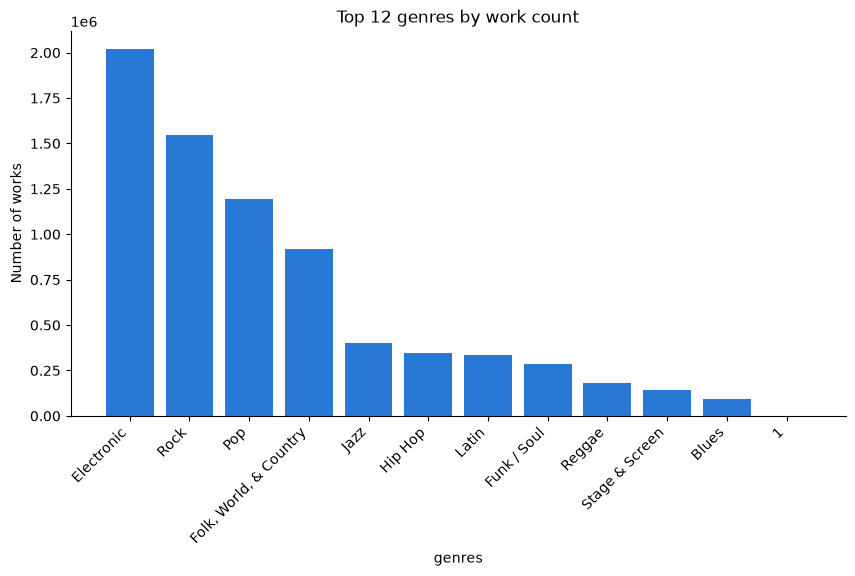

genres
Electronic                2018688
Rock                      1544051
Pop                       1194721
Folk, World, & Country     918610
Jazz                       401738
Hip Hop                    347037
Latin                      333290
Funk / Soul                283619
Reggae                     182280
Stage & Screen             141766
Blues                       91253
1                               8
Name: count, dtype: int64

In [9]:
from eda import top_n_tags  # reusable plotting function lives in src/eda.py

top_genres = top_n_tags(works_df, "genres", n=15)  # top 15 genres by total work count, kept for reuse in the trending step
top_genres

### Interpretation

The yearly series confirms the histogram: low and flat before 1960, steady growth through the 2000s, a peak of 191,013 works in 2020, then a sharp fall to 54,958 in 2026. That fall is a dump-cutoff artifact (recent releases are still being logged), so years after about 2022 should be read with caution. Genre is a small fixed taxonomy (12 values, so "top 15" covers all of them), led by Electronic (2,018,688), Rock (1,544,051) and Pop (1,194,721). One junk value, `"1"`, appears on only 8 works.

### Decision

No cleaning here. The `"1"` tag is too small for its own PENDING item and is just excluded from later genre breakdowns. `top_genres` is kept so the same list is reused below.

### Question: How does each top genre's work volume trend by year, which are rising, declining, or stable?

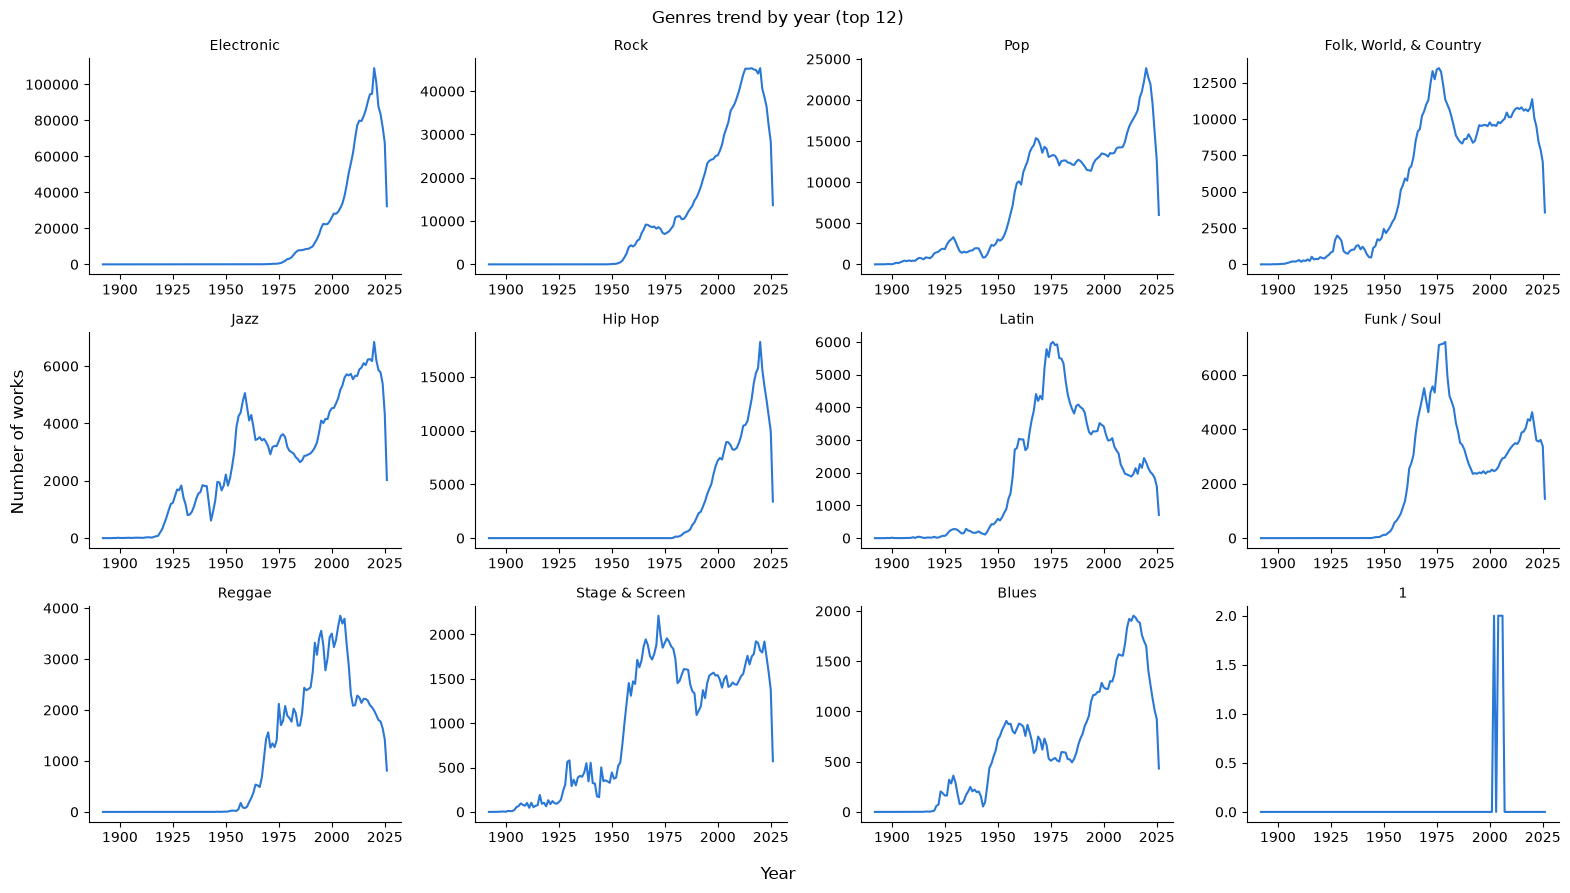

genres,1,Blues,Electronic,"Folk, World, & Country",Funk / Soul,Hip Hop,Jazz,Latin,Pop,Reggae,Rock,Stage & Screen
year,,,,,,,,,,,,
2022.0,0,1268,87723,9480,3598,14153,5868,2021,21959,1804,38669,1920
2023.0,0,1132,83514,8425,3550,12865,5779,1954,19585,1776,36495,1743
2024.0,0,1011,76275,7886,3612,11365,5388,1842,16157,1642,32123,1575
2025.0,0,925,67515,7035,3382,9934,4333,1589,12650,1422,28311,1376
2026.0,0,431,32303,3570,1446,3401,2027,712,6015,811,13686,572


In [10]:
from eda import plot_tag_trends  # reusable plotting function lives in src/eda.py

genre_trend_table = plot_tag_trends(works_df, top_genres, "genres")  # per-year work count for each top genre, as a small-multiples grid
genre_trend_table.tail()  # most recent years per genre, to check the post-2020 drop-off consistently across genres

### Interpretation

Each genre follows one of three shapes. Electronic, Rock, Pop, Hip Hop, Jazz, Blues and Folk/World/Country keep rising into the 2020 peak. Funk/Soul and Latin peak around 1978-1980, fall sharply, then recover without reaching the old peak. Reggae peaks around 2005 and declines, and Stage & Screen stays flat. The `"1"` tag again looks like noise (at most 2 works in any year).

### Decision

No cleaning here. `genre_trend_table` is kept for the missing-year-by-genre step.

### Question: Has the genre composition of works_df shifted over time, or has the top genre mix stayed stable?

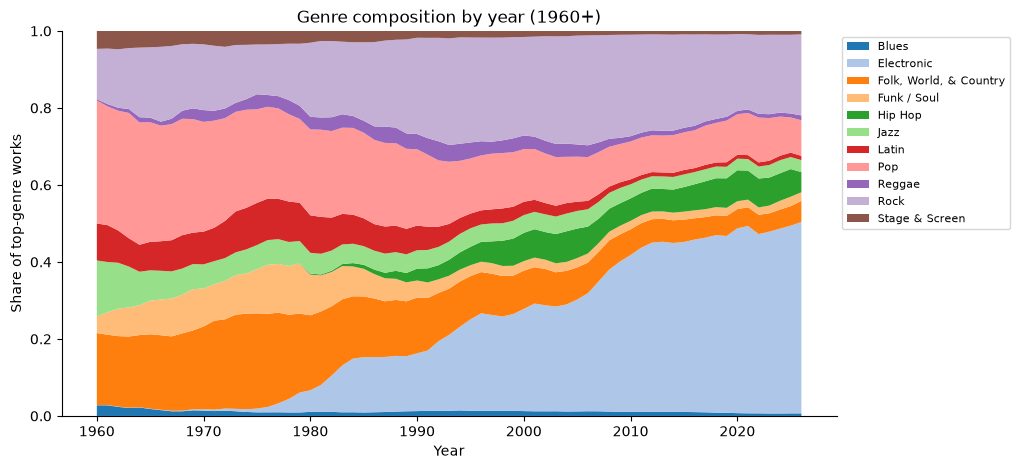

genres,Blues,Electronic,"Folk, World, & Country",Funk / Soul,Hip Hop,Jazz,Latin,Pop,Reggae,Rock,Stage & Screen
year,,,,,,,,,,,
2022.0,0.006728,0.465465,0.050302,0.019091,0.075097,0.031136,0.010724,0.116516,0.009572,0.205181,0.010188
2023.0,0.006402,0.472316,0.047648,0.020077,0.072758,0.032683,0.011051,0.110764,0.010044,0.206399,0.009858
2024.0,0.006363,0.480091,0.049636,0.022735,0.071534,0.033913,0.011594,0.101696,0.010335,0.202189,0.009913
2025.0,0.006680,0.487571,0.050804,0.024424,0.071740,0.031292,0.011475,0.091354,0.010269,0.204453,0.009937
2026.0,0.006633,0.497168,0.054945,0.022255,0.052344,0.031197,0.010958,0.092575,0.012482,0.210638,0.008804


In [11]:
from eda import plot_genre_share_by_year  # reusable plotting function lives in src/eda.py

genre_share_table = plot_genre_share_by_year(genre_trend_table)  # 100%-stacked share chart from 1960 on, capture full-range share table
genre_share_table.tail()  # most recent years' genre mix, to check against the post-2020 drop-off caveat

### Interpretation

The genre mix changed a lot between 1960 and 2026, mostly because Electronic grew from 0% to 49.7% of top-genre works. It passed Pop in 1992 and Rock in 2000 and has been the largest genre since. Rock rose to a peak of 28.6% in 2006 and is now 21.1%, while Pop fell from about 32% to 9.3%. Jazz, Blues and Stage & Screen declined almost steadily from 1960, and Hip Hop is the only other genre that rose from zero (5.2% now). Years before 1960 are left out because the yearly volume is too small for shares to be stable.

### Decision

No cleaning here. For modeling, genre composition is time-dependent, so a model using `year` should expect genre behavior to change over time.

## 3. Multivariate

### Question: Does missing-year concentrate in particular genres? (`"1"` fake-genre tag omitted, not a real category)

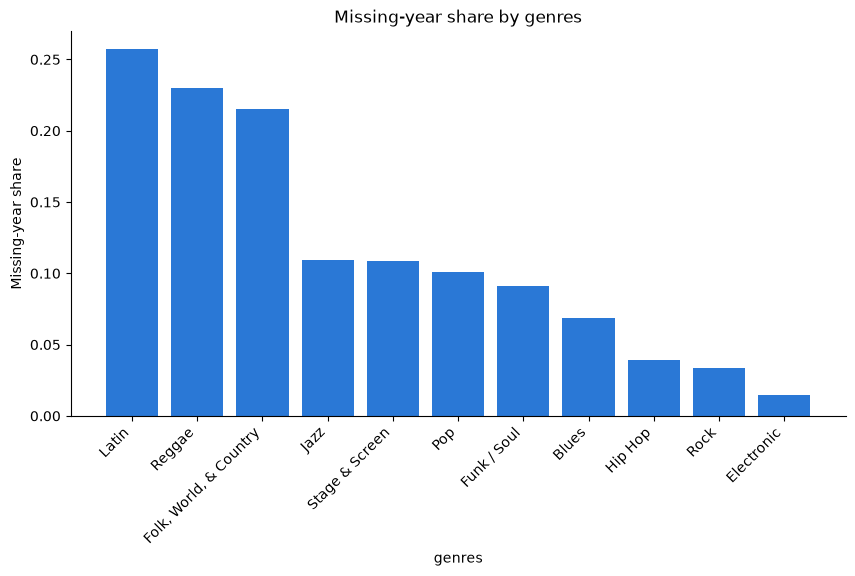

,total,missing,missing_share
genres,,,
Latin,333290,85704,0.257145
Reggae,182280,41966,0.230228
"Folk, World, & Country",918610,197434,0.214927
Jazz,401738,43822,0.109081
Stage & Screen,141766,15417,0.108750
Pop,1194721,120472,0.100837
Funk / Soul,283619,25773,0.090872
Blues,91253,6260,0.068600
Hip Hop,347037,13604,0.039200


In [12]:
from eda import missing_year_by_tag  # reusable plotting/summary function lives in src/eda.py

missing_year_genre_stats = missing_year_by_tag(works_df, top_genres, "genres")  # draw the bar chart, capture missing-year share per genre
missing_year_genre_stats

In [13]:
from eda import tag_year_distribution  # reusable summary function lives in src/eda.py

genre_year_stats = tag_year_distribution(works_df, top_genres, "genres")  # min/10th-percentile/median year per genre, among non-missing rows only
genre_confound_check = missing_year_genre_stats.join(genre_year_stats)  # merge missing-year share with each genre's year distribution, to check for an age confound
genre_confound_check.sort_values("missing_share", ascending=False)[["missing_share", "min", "p10", "median"]]

,missing_share,min,p10,median
genres,,,,
Latin,0.257145,1898.0,1961.0,1983.0
Reggae,0.230228,1937.0,1975.0,1998.0
"Folk, World, & Country",0.214927,1896.0,1960.0,1989.0
Jazz,0.109081,1896.0,1947.0,1991.0
Stage & Screen,0.108750,1895.0,1954.0,1985.0
Pop,0.100837,1892.0,1958.0,1992.0
Funk / Soul,0.090872,1922.0,1967.0,1985.0
Blues,0.068600,1914.0,1952.0,1998.0
Hip Hop,0.039200,1971.0,1998.0,2014.0


In [14]:
from eda import tag_confound_correlation  # reusable summary function lives in src/eda.py

tag_confound_correlation(genre_confound_check)  # Spearman r and p-value, missing_share vs each year-distribution stat

,spearman_r,p_value
min,-0.487473,0.128276
p10,-0.436364,0.179665
median,-0.721469,0.012205


### Interpretation

Missing-year rates differ a lot by genre: 25.7% for Latin versus 1.5% for Electronic, an 18x gap. Most of this follows how old each genre's catalog is: the older genres (Latin median year 1983, Funk/Soul 1985, Folk/World/Country 1989) have the highest rates, and the newer ones (Rock 2008, Electronic 2015) the lowest. The correlation between missing share and median year is -0.72 (p = 0.012, n = 11 genres), while the min-year and p10-year correlations are not significant. Catalog age explains most of the pattern, but genre-specific cataloging quality may still play a smaller role.

### Decision

No cleaning here. The missing-year strategy should key on work era first, with genre and `work_source` as secondary factors.

## 4. Styles

### Question: How many distinct styles exist in works_df, and what share of total works does the top-15 actually cover?

Unlike genres (a fixed 12-value taxonomy where top-15 is everything), styles is a much finer-grained tag set, so this checks up front how exhaustive a top-15 cut actually is before treating it as representative.

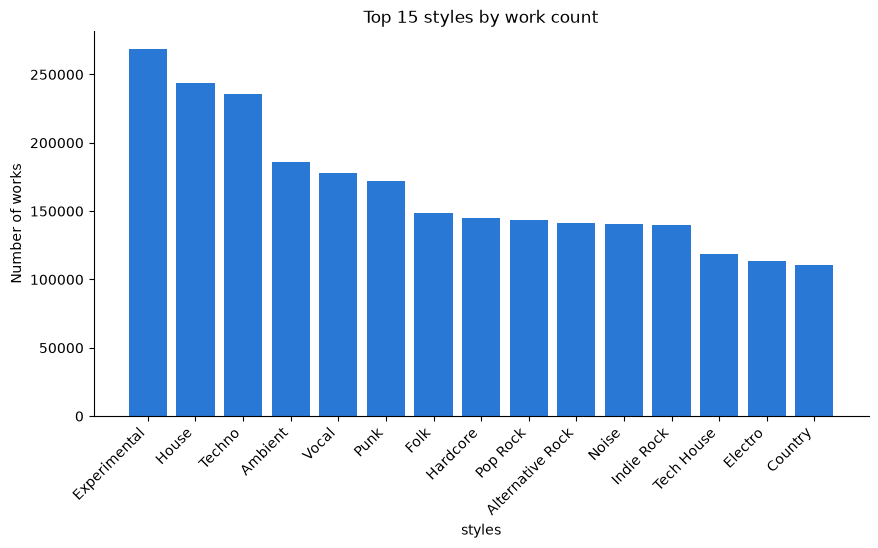

{'distinct_tag_count': 734,
 'total_works': 5949217,
 'works_covered_by_top_n': 2070269,
 'coverage_share': np.float64(0.34799016408377775)}

In [15]:
from eda import top_n_tags, style_scale_check  # reusable functions live in src/eda.py

top_styles = top_n_tags(works_df, "styles", n=15)  # top 15 styles by total work count, kept for reuse in the trending step
scale_check = style_scale_check(works_df, top_styles, "styles")  # distinct style count and top-15 coverage share
scale_check

### Interpretation

There are 734 distinct styles, far more than the 12 genres. The top 15 (Experimental, House, Techno, Ambient, Vocal and so on) cover only 34.8% of works (2,070,269 of 5,949,217), so most of the style signal sits in the long tail of 719 other styles.

### Decision

No cleaning here. Any top-N style analysis below is a partial slice, not a stand-in for the full style distribution.

### Question: How does each top style's work volume trend by year, rising, declining, or stable?

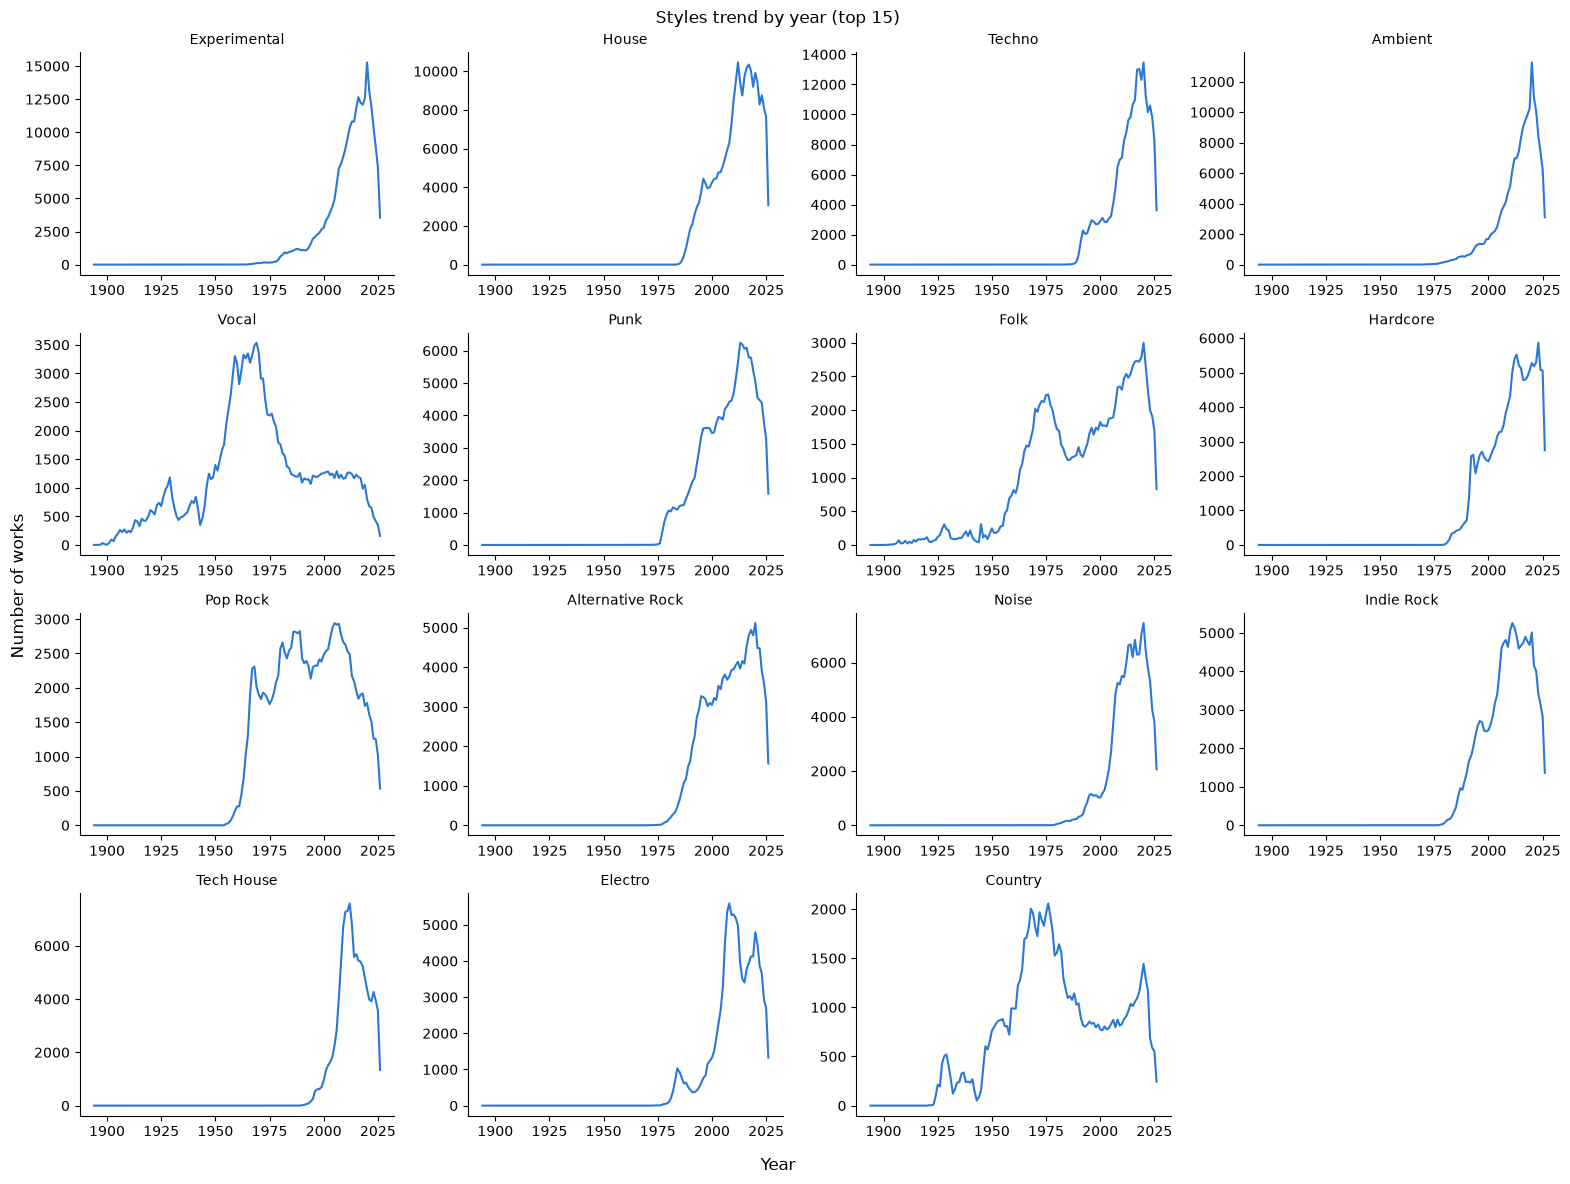

styles,Alternative Rock,Ambient,Country,Electro,Experimental,Folk,Hardcore,House,Indie Rock,Noise,Pop Rock,Punk,Tech House,Techno,Vocal
year,,,,,,,,,,,,,,,
2022.0,4478,10077,1170,3865,11951,2299,5296,8278,4016,5799,1510,4470,3909,10160,652
2023.0,3903,8466,686,3651,10346,1998,5864,8757,3421,5316,1261,4392,4267,10598,489
2024.0,3597,7383,589,2931,8897,1911,5081,8115,3145,4255,1255,3782,3949,9801,421
2025.0,3120,6241,552,2690,7363,1695,5057,7608,2829,3818,1023,3269,3566,8275,350
2026.0,1564,3102,244,1328,3548,829,2748,3083,1363,2064,534,1587,1342,3617,159


In [16]:
from eda import plot_tag_trends  # reusable plotting function lives in src/eda.py

style_trend_table = plot_tag_trends(works_df, top_styles, "styles")  # per-year work count for each top style, as a small-multiples grid
style_trend_table.tail()  # most recent years per style, to check the post-2020 drop-off consistently across styles

### Interpretation

Styles show the same three trend shapes as genres, only more extreme and tied to specific eras. Alternative Rock, Ambient, Experimental, Folk, Hardcore, Noise and Techno keep rising into 2020. Electro, House, Tech House, Indie Rock, Punk and Pop Rock peaked between the mid-2000s and mid-2010s and then declined. Country (peak 1976) and Vocal (peak 1969) peaked decades earlier and never recovered. Whether the catalog-age pattern seen for genres also holds at the style level is tested in the missing-year question below.

### Decision

No cleaning here. `style_trend_table` is kept for the missing-year-by-style step.

### Question: Does missing-year concentrate in particular styles, and is the age confound sharper here than at the genre level?

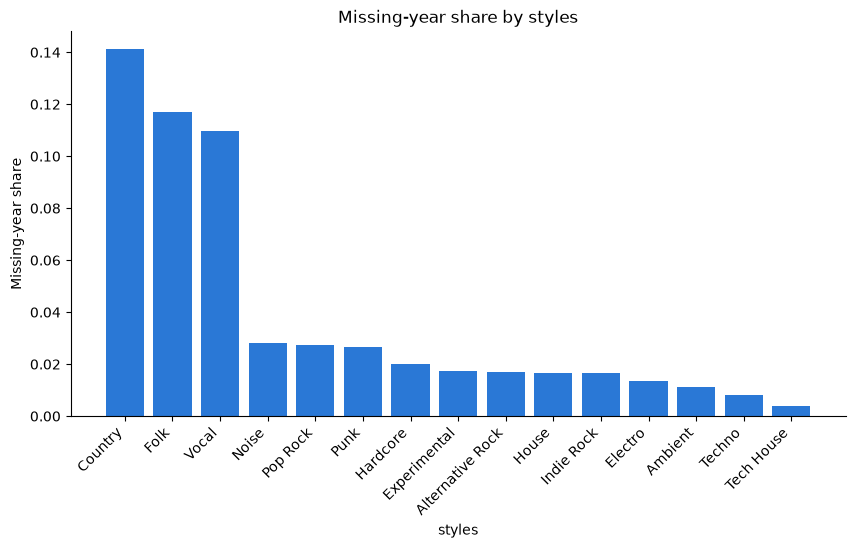

,missing_share,min,p10,median
styles,,,,
Country,0.141076,1901.0,1952.0,1978.0
Folk,0.116992,1896.0,1964.0,1996.0
Vocal,0.109564,1894.0,1934.0,1969.0
Noise,0.028320,1967.0,2003.0,2014.0
Pop Rock,0.027238,1955.0,1970.0,1994.0
Punk,0.026458,1966.0,1991.0,2010.0
Hardcore,0.020072,1978.0,1995.0,2012.0
Experimental,0.017366,1950.0,1998.0,2015.0
Alternative Rock,0.017031,1971.0,1993.0,2010.0


In [17]:
from eda import missing_year_by_tag, tag_year_distribution, tag_confound_correlation  # reusable functions live in src/eda.py

missing_year_style_stats = missing_year_by_tag(works_df, top_styles, "styles")  # draw the bar chart, capture missing-year share per style
style_year_stats = tag_year_distribution(works_df, top_styles, "styles")  # min/10th-percentile/median year per style, among non-missing rows only
style_confound_check = missing_year_style_stats.join(style_year_stats)  # merge missing-year share with each style's year distribution, to check for an age confound
style_confound_check.sort_values("missing_share", ascending=False)[["missing_share", "min", "p10", "median"]]

In [18]:
tag_confound_correlation(style_confound_check)  # Spearman r and p-value, missing_share vs each year-distribution stat

,spearman_r,p_value
min,-0.689286,0.004474
p10,-0.736372,0.001744
median,-0.666078,0.006707


### Interpretation

Missing-year share by style runs from 14.1% (Country) down to 0.40% (Tech House), a 36x spread versus 18x for genres. All three year-distribution statistics correlate significantly with missing share across the 15 styles (min r = -0.69, p10 r = -0.74, median r = -0.67), while at genre level only the median was significant. Old-skewing styles such as Country and Vocal have the highest missing rates, and the newest styles (Tech House, Techno, Ambient) the lowest. The age confound is therefore at least as strong for styles as for genres.

### Decision

No cleaning here. The age-first handling strategy holds at style level, so no style-specific rule is needed.

## 5. WHAT Target Base Rate

### Question: Across each artist's consecutive works (ordered chronologically, known-year works only), what fraction of transitions introduce at least one style never seen before in that artist's history? This is the literal WHAT definition from `docs/decisions.md`, checked here for the first time.

In [19]:
import yaml  # reads the modeling threshold from config.yaml
from eda import artist_style_transitions, what_base_rate  # reusable functions live in src/eda.py

with open('../config.yaml') as f:
    min_previous_works = yaml.safe_load(f)['what']['min_previous_works']  # existing modeling threshold, reused here

transitions = artist_style_transitions(works_df)  # one row per consecutive known-year transition, per artist
what_base_rate(transitions, min_previous_works)  # base rate over all transitions and over the modeling population

{'n_transitions': 4443714,
 'overall_base_rate': np.float64(0.23431075897323725),
 'n_restricted_transitions': 3254604,
 'restricted_base_rate': np.float64(0.18058172361368696)}

### Question: How much style diversity does an artist typically accumulate across their known-year works?

In [20]:
from eda import artist_style_diversity  # reusable function lives in src/eda.py

style_diversity = artist_style_diversity(works_df)  # distinct style count per artist, same eligible population as the transitions above
style_diversity.describe(percentiles=[.1, .25, .5, .75, .9, .99])

count    659307.000000
mean          3.686236
std           3.510604
min           0.000000
10%           1.000000
25%           2.000000
50%           3.000000
75%           5.000000
90%           8.000000
99%          17.000000
max         127.000000
Name: styles, dtype: float64

### Interpretation

Across 4,443,714 consecutive same-artist transitions, 23.4% introduce a style the artist never used before. For the modeling population (3+ prior works, the `config.yaml` cutoff) the rate is 18.1% over 3,254,604 transitions, about 1 in 5.5. That is neither near 0% nor near 100%, so the target is not degenerate. Most artists stay within a handful of styles (median 3, 90th percentile 8), with a long tail up to 127.

### Decision

The WHAT target is usable and worth modeling.

## 6. Cutoff Sensitivity

### Question: Is the WHAT base rate stable when the `min_previous_works` cutoff changes, or is the config.yaml value of 3 an arbitrary pick that drives the result?

In [21]:
from eda import what_cutoff_sensitivity  # reusable function lives in src/eda.py

what_cutoff_sensitivity(transitions, [2, 3, 5])  # transition count and new-style rate at each candidate cutoff

,min_previous_works,n_transitions,new_style_rate
0,2,3784407,0.201780
1,3,3254604,0.180582
2,5,2565515,0.154524


### Interpretation

The base rate falls smoothly as the cutoff tightens: 20.2% with 2+ prior works (3,784,407 transitions), 18.1% with 3+ (3,254,604) and 15.5% with 5+ (2,565,515), about 2.5 points per step. There is no jump or collapse near any cutoff, so the choice of 3 is not driving the result.

### Decision

Keep `min_previous_works = 3` from `config.yaml`. This resolves the matching PENDING item in `docs/decisions.md`.

## 7. Hypothesis Testing

### Hypothesis 1: Does an artist's new-style introduction rate change with how many prior works they have?

**Explanation:** If the rate is the same for artists with 3 prior works and artists with 50+, history length carries no signal and is not worth feeding the WHAT model. If it differs, prior-work count is a real predictor and a confound to control for in evaluation.

**H0:** `is_new_style` is independent of the prior-work bucket (3-5, 6-10, 11-20, 21-50, 51+); the new-style rate is equal across all five buckets.

**H1:** `is_new_style` depends on the prior-work bucket; at least one bucket's new-style rate differs from the others.

**Test used and why:** Chi-square test of independence on the 5 x 2 contingency table (bucket x new style yes/no). Both variables are categorical once prior-work count is bucketed, and every expected cell count is far above 5, so the test's size assumption holds. Caveat: transitions from the same artist are not fully independent (one artist contributes many transitions, across several buckets), so the p-value is overstated and the size of the rate gap matters more than the p-value alone.

In [22]:
from eda import new_style_rate_by_prior_work_bucket, prior_work_bucket_chi_square  # reusable functions live in src/eda.py

bucket_rates = new_style_rate_by_prior_work_bucket(transitions, min_previous_works)  # rate and sample size per prior-work bucket
chi_square_result = prior_work_bucket_chi_square(transitions, min_previous_works)  # independence test, new_style vs bucket

print(bucket_rates.to_string())  # per-bucket sample size, new-style count, and rate
print(f"chi2 = {chi_square_result['chi2']:.2f}, dof = {chi_square_result['dof']}, p = {chi_square_result['p_value']:.3e}")  # test statistic and p-value
print("Reject null (p < 0.05)" if chi_square_result['p_value'] < 0.05 else "Fail to reject null (p >= 0.05)")  # test verdict at alpha 0.05

                   n_transitions  new_style_count  new_style_rate
prior_work_bucket                                                
3-5                       927574           249293        0.268758
6-10                      729148           150468        0.206361
11-20                     632029            99337        0.157172
21-50                     576937            64493        0.111785
51+                       388916            24131        0.062047
chi2 = 109737.05, dof = 4, p = 0.000e+00
Reject null (p < 0.05)


**Interpretation:** Reject H0 (chi-square = 109,737, 4 degrees of freedom, p < 0.000001). The new-style rate falls steadily with history length: 26.9% for 3-5 prior works, 20.6% for 6-10, 15.7% for 11-20, 11.2% for 21-50 and 6.2% for 51+, a 4x gap between the first and last bucket. With over 3 million transitions almost any difference would be significant, but this gap is large, so it matters in practice. Prior-work count is a strong WHAT feature, and the overall 18.1% rate hides very different rates by history length, so evaluation should be reported per bucket. The test cannot say whether the drop is real settling or an artifact of sparser tags in early catalogs.

### Hypothesis 2: Does genre affect an artist's style-transition rate independent of their prior-work count?

**Explanation:** Hypothesis 1 showed the new-style rate falls sharply with history length. Genres also differ in age and in how many styles they offer, so a raw genre gap could just be a seniority gap in disguise (a genre full of 3-5 work artists would look more experimental than a genre full of 50+ work artists). Comparing genres inside each prior-work bucket removes that confound. If genre still matters inside every bucket, it is a real predictor on its own and a candidate feature for the WHAT model. If the effect vanishes or flips with seniority, genre only matters for certain career stages.

**H0:** Within each prior-work bucket (3-5, 6-10, 11-20, 21-50, 51+), `is_new_style` is independent of genre; the new-style rate is equal across all genres.

**H1:** In at least one bucket, `is_new_style` depends on genre; at least one genre's new-style rate differs from the others. A second, descriptive question is whether the genre ranking (highest to lowest rate) stays the same across buckets.

**Test used and why:** One chi-square test of independence per bucket, each on an 11 x 2 contingency table (genre x new style yes/no). Both variables are categorical, and the smallest expected cell count in every bucket is far above 5 (reported below), so the test's size assumption holds. Running the test separately per bucket, instead of one pooled test, is what holds prior-work count fixed. Because chi-square statistics grow with sample size and the buckets differ in size, Cramer's V is reported next to each result as a comparable effect size. Ranking consistency is read from the rank of each genre per bucket and the Spearman correlation of the rate columns between buckets. Caveats: (1) a transition is assigned to a genre only when the work carries exactly one genre (about 79% of transitions); multi-genre works have no single genre cell and are dropped, and the `"1"` junk tag is excluded. (2) Transitions from the same artist are not independent, so p-values are overstated and effect size matters more than significance. (3) The test does not separate a real genre effect from genre differences in how many style tags a genre offers.

In [23]:
from eda import new_style_rate_by_genre_and_bucket, genre_bucket_sample_sizes, genre_chi_square_by_bucket, genre_rank_consistency  # reusable functions live in src/eda.py

genre_bucket_rates = new_style_rate_by_genre_and_bucket(transitions, min_previous_works)  # new-style rate, genre x prior-work bucket
genre_bucket_counts = genre_bucket_sample_sizes(transitions, min_previous_works)  # transitions behind each rate, to judge small cells
genre_chi_square = genre_chi_square_by_bucket(transitions, min_previous_works)  # one independence test per bucket
rank_consistency = genre_rank_consistency(genre_bucket_rates)  # genre ranks per bucket and rank agreement between buckets

print(genre_bucket_rates.round(3).to_string())  # rate per genre and bucket, genres ordered by overall average
print(genre_bucket_counts.to_string())  # transition count per genre and bucket
print(genre_chi_square.to_string())  # chi2, dof, p-value, Cramer's V and smallest expected count per bucket
print(rank_consistency["ranks"].to_string())  # genre rank per bucket (1 = highest rate) and how far it moves
print(rank_consistency["bucket_spearman"].round(3).to_string())  # rank correlation between buckets

prior_work_bucket         3-5   6-10  11-20  21-50    51+
genre                                                    
Electronic              0.302  0.219  0.159  0.105  0.051
Stage & Screen          0.281  0.197  0.150  0.108  0.063
Jazz                    0.238  0.182  0.133  0.094  0.045
Rock                    0.227  0.170  0.126  0.086  0.051
Blues                   0.200  0.147  0.111  0.092  0.072
Latin                   0.212  0.150  0.112  0.076  0.051
Funk / Soul             0.209  0.148  0.112  0.078  0.050
Reggae                  0.208  0.142  0.091  0.059  0.019
Hip Hop                 0.149  0.109  0.076  0.053  0.039
Pop                     0.144  0.104  0.077  0.052  0.027
Folk, World, & Country  0.120  0.085  0.064  0.048  0.032
prior_work_bucket          3-5    6-10   11-20   21-50     51+
genre                                                         
Blues                     4544    3557    2946    2641    1690
Electronic              280295  243041  220444  195940  1

**Interpretation:** Reject H0 in all five buckets (chi-square from 17,557 at 3-5 prior works down to 1,182 at 51+, all p < 1e-247). With this many transitions significance is guaranteed, so the effect size is what matters: Cramer's V falls from 0.155 (3-5) to 0.062 (51+), meaning genre matters at every stage but its effect shrinks as history grows. The ranking is fairly stable at the top and bottom: Electronic and Stage & Screen lead, and Pop and Folk/World/Country stay near the bottom (3-5 works: Electronic 30.2% vs Folk/World/Country 12.0%). The spread between genres shrinks from about 18 points at 3-5 works to about 5 points at 51+, and the order reshuffles among senior artists. For the project, genre is worth including as a feature, interacting with prior-work count (tree models do this natively), and evaluation should be reported per genre within bucket. Not answered here: whether the gap is real behavior or a taxonomy artifact, and multi-genre works (about 21% of transitions) were excluded from this test.

### Hypothesis 3: Does a longer gap (in years) between two consecutive works make it more likely that the next work introduces a new style?

**Explanation:** A long silence could mean a hiatus followed by a reinvention, or just a quiet stretch with no stylistic meaning. If the gap carries no signal, the time-since-last-work feature is not worth building for the WHAT model. If longer gaps go with more new styles, gap length is a real predictor, and it is also the quantity the WHEN side of the project predicts, so the two targets would be linked. Only transitions where both works have a known year are used (`year_gap` is the difference between the two years, 0 for works released in the same year).

**H0:** The distribution of `year_gap` is the same for transitions that introduce a new style and for transitions that do not.

**H1:** `year_gap` tends to be larger (or smaller) before a transition that introduces a new style.

**Test used and why:** Normality of `year_gap` is checked first, with a histogram and a D'Agostino-Pearson test (on a fixed 5,000-row sample, since on millions of rows any tiny deviation from normal is rejected) plus skewness and kurtosis. If the gap is clearly not normal, a t-test is not valid and the Mann-Whitney U test is used instead: a rank-based test of whether one group tends to have larger values, with no normality assumption. Two groups (new style yes/no) make Mann-Whitney the right choice over Kruskal-Wallis, which is for three or more groups. The rank-biserial correlation is reported as the effect size (0 = no difference, 1 = new-style transitions always follow longer gaps). The test is run pooled and inside each prior-work bucket, since H1 showed prior-work count drives the new-style rate. A descriptive table of the new-style rate per gap bucket shows the shape. Caveats: (1) many gaps are tied (most transitions are 0 or 1 year), which Mann-Whitney handles but which compresses the effect size. (2) Transitions from the same artist are not independent, so p-values are overstated and effect size matters more.

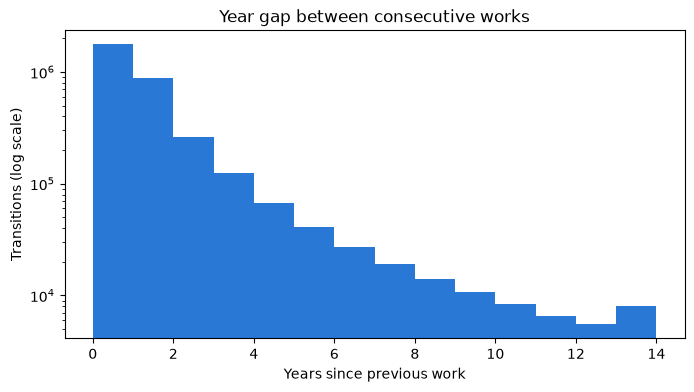

{'n': 3254604, 'mean': np.float64(1.1453642286434846), 'median': np.float64(0.0), 'skewness': np.float64(7.767484495675451), 'excess_kurtosis': np.float64(96.4945117734835), 'normaltest_stat': np.float64(5765.520657404493), 'normaltest_p': np.float64(0.0), 'sample_size': 5000}


In [24]:
from eda import plot_year_gap_distribution  # reusable plotting function lives in src/eda.py

gap_normality = plot_year_gap_distribution(transitions, min_previous_works)  # histogram of year_gap plus skewness, kurtosis and normality test
print(gap_normality)  # n, mean, median, skewness, excess kurtosis, test statistic and p-value

In [25]:
from eda import new_style_rate_by_year_gap_bucket, year_gap_mann_whitney  # reusable functions live in src/eda.py

gap_bucket_rates = new_style_rate_by_year_gap_bucket(transitions, min_previous_works)  # new-style rate and sample size per year-gap bucket
gap_mann_whitney = year_gap_mann_whitney(transitions, min_previous_works)  # Mann-Whitney U on year_gap by new style, pooled and per prior-work bucket

print(gap_bucket_rates.round(3).to_string())  # descriptive shape of the relationship
print(gap_mann_whitney.to_string())  # group sizes, median gaps, U, p-value and rank-biserial effect size

                 n_transitions  new_style_count  new_style_rate
year_gap_bucket                                                
0                      1759671           244775           0.139
1                       874612           184494           0.211
2-3                     385033            94961           0.247
4-5                     108807            28562           0.263
6-10                     79038            21482           0.272
11+                      47443            13448           0.283
       n_new_style  n_no_new_style  median_gap_new_style  median_gap_no_new_style        u_stat  p_value  rank_biserial
all       587722.0       2666882.0                   1.0                      0.0  9.159105e+11      0.0       0.168711
3-5       249293.0        678281.0                   1.0                      1.0  9.305078e+10      0.0       0.100602
6-10      150468.0        578680.0                   1.0                      0.0  4.845580e+10      0.0       0.112995
11-20   

**Interpretation:** `year_gap` is far from normal (median 0, mean 1.15, skewness 7.8), so Mann-Whitney U was used instead of a t-test. Reject H0 pooled and in every prior-work bucket: transitions that introduce a new style follow longer gaps (median 1 year versus 0). The new-style rate rises from 13.9% at a same-year gap to 21.1% (1 year), 24.7% (2-3) and about 27-28% (4+), so most of the rise happens in the first three years. The effect is small (rank-biserial 0.169 pooled, 0.10 to 0.14 within buckets), and 54% of transitions are same-year releases such as singles and albums from one project. For the project, `year_gap` is a usable but weak feature, best used in a bucketed or saturating form, with evaluation still reported per bucket.

### Hypothesis 4: Do artists with more distinct styles in their prior history have a higher or lower chance of adding another new one (saturation vs. exploration)?

**Explanation:** Two opposite stories are possible. Saturation: an artist who already covers many styles has used up most of what fits them, so a new one gets less likely. Exploration: an artist with a wide vocabulary is the kind who keeps moving, so a new style gets more likely. H1 used prior-work count; this uses prior style count (distinct styles seen before the work), which can separate "has done a lot" from "has done a lot of different things". The two are strongly linked (more works means more styles), so the test is run both pooled and inside each prior-work bucket to keep history length from hiding the effect.

**H0:** `is_new_style` is independent of the prior-style bucket (0, 1, 2, 3-4, 5-8, 9+ distinct styles); the new-style rate is equal across all six buckets.

**H1:** `is_new_style` depends on the prior-style bucket. A rate that falls with style count supports saturation; a rate that rises supports exploration.

**Test used and why:** Same as H1: chi-square test of independence on a 6 x 2 contingency table (bucket x new style yes/no), with Cramer's V as the effect size and the smallest expected cell count reported to check the size assumption. Style count is bucketed so both variables are categorical. The pooled test is then repeated inside each prior-work bucket (3-5, 6-10, 11-20, 21-50, 51+), and the rate table shows the direction. Caveats: (1) transitions from the same artist are not independent, so p-values are overstated and effect size matters more. (2) Prior style count partly measures how richly an artist's works are tagged, so a high count can reflect tagging habits as well as real stylistic range; the test cannot separate the two.

In [26]:
from eda import (  # reusable functions live in src/eda.py
    new_style_rate_by_prior_style_bucket, prior_style_bucket_chi_square,
    prior_style_chi_square_by_work_bucket, new_style_rate_by_prior_style_and_work_bucket,
)

style_bucket_rates = new_style_rate_by_prior_style_bucket(transitions, min_previous_works)  # pooled rate and sample size per prior-style bucket
style_chi_square = prior_style_bucket_chi_square(transitions, min_previous_works)  # pooled independence test, new_style vs prior-style bucket
style_chi_square_by_work = prior_style_chi_square_by_work_bucket(transitions, min_previous_works)  # same test inside each prior-work bucket
style_work_rates = new_style_rate_by_prior_style_and_work_bucket(transitions, min_previous_works)  # rate, prior-style bucket x prior-work bucket

print(style_bucket_rates.round(3).to_string())  # pooled sample size, new-style count, and rate
print(f"pooled: chi2 = {style_chi_square['chi2']:.2f}, dof = {style_chi_square['dof']}, p = {style_chi_square['p_value']:.3e}, Cramer's V = {style_chi_square['cramers_v']:.3f}, min expected = {style_chi_square['min_expected_count']:.0f}")  # pooled test summary
print(style_chi_square_by_work.to_string())  # chi2, p-value, Cramer's V and smallest expected count per prior-work bucket
print(style_work_rates.round(3).to_string())  # rate by prior-style bucket (rows) inside each prior-work bucket (columns)

                    n_transitions  new_style_count  new_style_rate
prior_style_bucket                                                
0                           68950            11577           0.168
1                          364810            54035           0.148
2                          453028            78231           0.173
3-4                        807197           155454           0.193
5-8                        879096           172375           0.196
9+                         681523           116050           0.170
pooled: chi2 = 5566.15, dof = 5, p = 0.000e+00, Cramer's V = 0.041, min expected = 12451
       n_transitions          chi2  dof  p_value  cramers_v  min_expected_count
3-5         927574.0  23479.883237  5.0      0.0   0.159101         5138.654339
6-10        729148.0  20889.859839  5.0      0.0   0.169262         3274.129927
11-20       632029.0  15529.581631  5.0      0.0   0.156751         1067.352237
21-50       576937.0   8403.960576  5.0      0.0   0.12

**Interpretation:** Reject H0, but the pooled and controlled answers differ. Pooled, the pattern is weak and humped (Cramer's V = 0.041; 16.8% at 0 prior styles, 14.8% at 1, up to 19.6% at 5-8, then 17.0% at 9+). Inside each prior-work bucket the pattern is clean: more prior styles means a higher chance of another new one (for example 20.9% to 50.7% at 3-5 prior works, 2.0% to 7.3% at 51+), with Cramer's V between 0.07 and 0.17. This supports exploration over saturation, and the pooled view hides it because artists with many styles also have long catalogs, which have low rates (H1). For the project, prior style count should be a feature used together with prior-work count, and any feature-importance read should be done within prior-work bucket.

### Hypothesis 5: Do artists with `year_missing=True` have a different new-style transition rate than those without?

**Explanation:** The transitions table can only order works that have a year, so undated works never appear as a transition. `year_missing` is therefore defined at the artist level: True if the artist has at least one undated work, meaning the history behind their transitions is incomplete. If the rate differs, either the missing-year problem is not random with respect to stylistic behavior (it should enter the model as a feature, and the decision to keep these artists is backed by more than coverage), or incomplete histories distort the target itself (the gaps hide earlier styles and change what counts as "new"). If the rate is the same, the flag only matters for coverage and evaluation reporting.

**H0:** `is_new_style` is independent of `year_missing`; the new-style rate is the same for artists with and without undated works.

**H1:** `is_new_style` depends on `year_missing`; the two groups have different new-style rates.

**Test used and why:** Chi-square test of independence on the 2 x 2 contingency table (year_missing x new style yes/no), as in H1; both variables are binary and the smallest expected count is reported to confirm the size assumption. Cramer's V is reported as the effect size. Because artists with undated works are likely to have larger catalogs and H1 showed the rate falls with catalog size, the rate gap is also shown inside each prior-work bucket to check whether the pooled gap survives holding history length fixed. Caveat: transitions from the same artist are not independent, so the p-value is overstated and effect size matters more.

In [27]:
from eda import new_style_rate_by_year_missing, year_missing_chi_square, new_style_rate_by_year_missing_and_work_bucket  # reusable functions live in src/eda.py

missing_rates = new_style_rate_by_year_missing(transitions, min_previous_works)  # pooled rate and sample size for year_missing False vs True
missing_chi_square = year_missing_chi_square(transitions, min_previous_works)  # 2 x 2 independence test, new_style vs year_missing
missing_rates_by_work = new_style_rate_by_year_missing_and_work_bucket(transitions, min_previous_works)  # rate by year_missing inside each prior-work bucket, plus the gap

print(missing_rates.round(3).to_string())  # pooled sample size, new-style count, and rate per group
print(f"chi2 = {missing_chi_square['chi2']:.2f}, dof = {missing_chi_square['dof']}, p = {missing_chi_square['p_value']:.3e}, Cramer's V = {missing_chi_square['cramers_v']:.3f}, min expected = {missing_chi_square['min_expected_count']:.0f}")  # test statistic, p-value, effect size, size check
print(missing_rates_by_work.round(3).to_string())  # rates and True-minus-False gap per prior-work bucket

              n_transitions  new_style_count  new_style_rate
year_missing                                                
False               2104953           420197           0.200
True                1149651           167525           0.146
chi2 = 14600.77, dof = 1, p = 0.000e+00, Cramer's V = 0.067, min expected = 207606
prior_work_bucket     3-5   6-10  11-20  21-50    51+
year_missing                                         
False               0.272  0.210  0.160  0.112  0.055
True                0.255  0.196  0.152  0.112  0.065
gap (True - False) -0.017 -0.014 -0.008 -0.000  0.010


**Interpretation:** Reject H0: artists with undated works have a lower new-style rate (14.6% versus 20.0%, Cramer's V = 0.067), and they account for 35% of modeling-population transitions. Most of the gap is composition, not behavior, because these artists have longer catalogs (23.7% of their transitions fall in the 51+ bucket versus 5.6% for the rest). With prior-work count held fixed, the gap shrinks to -1.7, -1.4, -0.8, 0.0 and +1.0 points across the five buckets, so `year_missing` is not a strong independent signal. For the project, this supports keeping these artists instead of dropping them; `year_missing` can still be a cheap feature, and evaluation should report results split by it. Not answered here: the flag is binary, so it does not say how many works are undated (`artist_undated_work_count` in `snapshots.py` does).

### Hypothesis 6: Does the chance that an artist releases something next year depend on how many years have passed since their last release?

**Explanation:** Hypotheses 1 to 5 study the WHAT target, so they use the transitions table. This hypothesis covers WHEN (does the artist release next year?), so it uses the snapshots table. It tests the main timing signal of the WHEN model, the years since the last release. The test describes a relationship in the data; all models are already locked and nothing is fitted, scored or changed here.

**H0:** `next_1y` (the artist has activity in year Y+1) is independent of the years-since-last-Work bucket (1, 2, 3-4, 5-9, 10+); the next-year release rate is equal across all five buckets.

**H1:** `next_1y` depends on the years-since-last-Work bucket; at least one bucket's rate differs from the others.

**Data:** the snapshots table (path from `config.yaml`, not rebuilt), one row per artist-year (the first snapshot of each artist-year, `works_so_far_this_year == 1`). Rows need `history_count >= 1`, `years_since_last >= 1` and a resolved `next_1y` label. All years from the earliest up to 2022 are used, so that Y+1 is at most 2023, the completeness rule the project uses for labels; later years have incomplete loading. Development years are not singled out because Hypotheses 1 to 5 also use the whole history and no model decision depends on this test.

**Test used and why:** Chi-square test of independence on a 5 x 2 contingency table (gap bucket x next year yes/no). Both variables are categorical once the gap is bucketed, and the smallest expected count is reported to confirm the size assumption. Cramer's V is the effect size. As in Hypothesis 2, the test is repeated inside buckets of `history_count` (1-2, 3-5, 6-10, 11-20, 21+) to see whether the gap effect is only a catalog-length effect. Caveat: rows of the same artist are not independent, so p-values are overstated and the rate gap and Cramer's V are the stronger evidence. With this many rows significance is guaranteed.

In [28]:
import yaml  # read the snapshots path from config.yaml
from eda import load_when_gap_rows, next_year_rate_by_gap_bucket, gap_bucket_chi_square  # reusable functions live in src/eda.py
with open('../config.yaml') as config_file:  # project configuration
    snapshots_path = '../' + yaml.safe_load(config_file)['paths']['snapshots']  # cached snapshots table, not rebuilt
gap_rows = load_when_gap_rows(snapshots_path)  # one row per artist-year, years up to 2022, resolved label
gap_rates = next_year_rate_by_gap_bucket(gap_rows)  # rows, releases and next-year rate per gap bucket
gap_test = gap_bucket_chi_square(gap_rows)  # independence test, next_1y vs gap bucket
print(gap_rates.round(4).to_string())  # counts and rate per bucket
print(f"rows = {gap_test['n_rows']:,}, artists = {gap_rows['artist_id'].nunique():,}, years {gap_rows['year'].min()} to {gap_rows['year'].max()}")  # size and span of the sample
print(f"chi2 = {gap_test['chi2']:.2f}, dof = {gap_test['dof']}, p = {gap_test['p_value']:.3e}, Cramer's V = {gap_test['cramers_v']:.3f}, min expected = {gap_test['min_expected_count']:,.0f}")  # test statistic, p-value, effect size, size assumption
print("Reject null (p < 0.05)" if gap_test['p_value'] < 0.05 else "Fail to reject null (p >= 0.05)")  # test verdict at alpha 0.05

             n_rows  released_next_year    rate
gap_bucket                                     
1           1134284            621814.0  0.5482
2            393882            132600.0  0.3366
3-4          297765             69567.0  0.2336
5-9          173051             30475.0  0.1761
10+           86446             10771.0  0.1246
rows = 2,085,428, artists = 578,620, years 1896 to 2022
chi2 = 203924.55, dof = 4, p = 0.000e+00, Cramer's V = 0.313, min expected = 35,866
Reject null (p < 0.05)


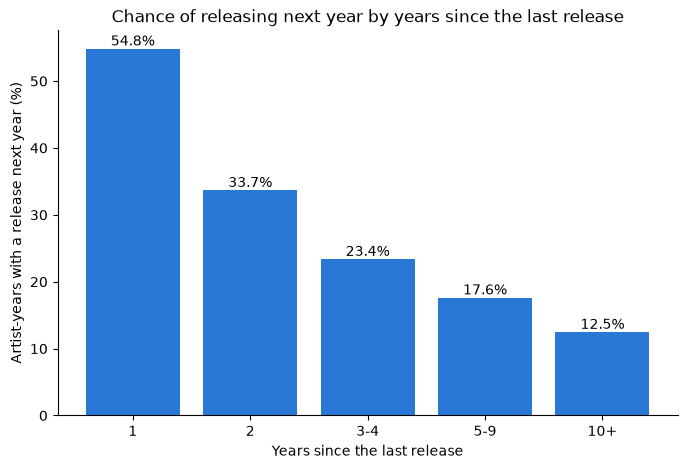

In [29]:
from eda import plot_next_year_rate_by_gap  # reusable chart function lives in src/eda.py
plot_next_year_rate_by_gap(gap_rates)  # pooled next-year release rate per gap bucket

In [30]:
from eda import gap_chi_square_by_history_bucket  # reusable function lives in src/eda.py
gap_by_history = gap_chi_square_by_history_bucket(gap_rows)  # same test inside each history_count bucket
print(gap_by_history.round(4).to_string())  # rows, chi-square, p-value, Cramer's V and rate per gap bucket

                n_rows        chi2  p_value  cramers_v  rate_gap_1  rate_gap_2  rate_gap_3-4  rate_gap_5-9  rate_gap_10+
history_bucket                                                                                                          
1-2             754999  44925.2297      0.0     0.2439      0.4410      0.2920        0.2111        0.1714        0.1284
3-5             500776  43601.3940      0.0     0.2951      0.4922      0.3045        0.2027        0.1484        0.1064
6-10            331195  32099.9331      0.0     0.3113      0.5717      0.3637        0.2536        0.1817        0.1286
11-20           240098  25730.8908      0.0     0.3274      0.6425      0.4227        0.2954        0.2139        0.1381
21+             258360  32702.5444      0.0     0.3558      0.7305      0.4871        0.3577        0.2451        0.1407


**Interpretation:** Reject H0 (chi-square = 203,925, 4 degrees of freedom, p < 1e-300, Cramer's V = 0.313, on 2,085,428 artist-years of 578,620 artists, 1896 to 2022). The chance of releasing next year falls steadily with the years since the last release: 54.8% after 1 year, 33.7% after 2, 23.4% after 3-4, 17.6% after 5-9 and 12.5% after 10+, a 4.4x difference between the first and last bucket. The effect is large (V of 0.313 is the strongest in this section), and the rate gap and V carry the evidence; rows of the same artist are not independent, so the p-value is overstated. Inside the history_count buckets the test is still rejected everywhere (chi-square between 25,731 and 44,925, all p < 1e-300) and the effect does not shrink: Cramer's V is 0.244 (1-2 works), 0.295, 0.311, 0.327 and 0.356 (21+ works). The gap effect is therefore not just catalog length. It is stronger for long catalogs: after 1 year the rate is 44.1% for 1-2 works and 73.1% for 21+, while after 10+ years all buckets sit between 10.6% and 14.1%. The pooled rate before the control mixes both effects (long catalogs are more active, short ones have longer gaps). For the project this confirms years since the last release as a strong timing signal for WHEN, together with catalog length. Not answered here: the test is descriptive and does not say how much a model gains from the feature, and it uses the first snapshot of each artist-year only.

## 8. Transformations and Correlations

### Question: are the right-skewed count variables of the transitions table close to normal, does a log transform help, and how strongly do the numeric variables move together?

The three count columns of the transitions table are `prior_work_count`, `year_gap` and `prior_style_count`. They are the numeric variables behind Hypotheses 1, 3 and 4, and counts of this kind have a long right tail. The tables below use the modeling population (`min_previous_works` and up) and show, for each column, the skewness before and after `log1p` (the logarithm of one plus the value, which keeps the zeros defined) and a D'Agostino-Pearson normality test. The test runs on one fixed-seed random sample of 5,000 rows per column (seed 0, the same rows before and after the transform), because on millions of rows any normality test rejects for a tiny deviation. Skewness and excess kurtosis use all rows. The second table gives the Spearman correlation, its two-sided p-value and n for every pair of the three columns and the 0/1 target `is_new_style`. Six pairs are tested, so a Bonferroni threshold of 0.05 / 6 is shown next to each p-value.

In [31]:
from eda import transformation_check  # reusable function lives in src/eda.py

skew_table = transformation_check(transitions, min_previous_works)  # skewness, kurtosis and normality test per column, raw and log1p
print(skew_table.to_string(float_format=lambda x: f"{x:.4g}"))  # one row per column and version, p-values in scientific form


            variable version        n  sample_size  skewness  excess_kurtosis  normaltest_stat  normaltest_p
0   prior_work_count     raw  3254604         5000     7.343            80.75             6026             0
1   prior_work_count   log1p  3254604         5000    0.9232           0.4915              465     1.04e-101
2           year_gap     raw  3254604         5000     7.767            96.49             5766             0
3           year_gap   log1p  3254604         5000     1.524            2.706             1489             0
4  prior_style_count     raw  3254604         5000      3.35            23.18             3386             0
5  prior_style_count   log1p  3254604         5000    0.1544        -0.003527            24.94      3.84e-06


In [32]:
from eda import spearman_table  # reusable function lives in src/eda.py

corr_table = spearman_table(transitions, min_previous_works)  # Spearman r, p-value and n for every pair of numeric columns
print(corr_table.to_string(float_format=lambda x: f"{x:.4g}"))  # r, p-value and the Bonferroni threshold


          variable_a         variable_b        n  spearman_r    p_value  bonferroni_alpha  below_bonferroni
0   prior_work_count           year_gap  3254604     -0.2555          0          0.008333              True
1   prior_work_count  prior_style_count  3254604      0.5893          0          0.008333              True
2   prior_work_count       is_new_style  3254604      -0.188          0          0.008333              True
3           year_gap  prior_style_count  3254604     -0.1274          0          0.008333              True
4           year_gap       is_new_style  3254604       0.124          0          0.008333              True
5  prior_style_count       is_new_style  3254604     0.01177 4.596e-100          0.008333              True


### Interpretation

**Skewness.** All three counts are strongly right-skewed (skewness 7.34 for `prior_work_count`, 7.77 for `year_gap`, 3.35 for `prior_style_count`, excess kurtosis 81, 96 and 23). `log1p` cuts the skewness a lot for each of them: 0.92, 1.52 and 0.15. Only `prior_style_count` ends up close to symmetric (skewness 0.15, excess kurtosis about 0). `year_gap` stays clearly skewed after the transform (1.52).

**Normality.** The D'Agostino-Pearson test still rejects normality for all three columns after `log1p`, on a fixed-seed sample of 5,000 rows each (p of about 1e-101, 0 and 3.8e-06; a p-value printed as 0 is below the floating point range). The transform reduces the skew but does not reach a normal shape. These are whole-number counts with many tied values, and `year_gap` has a median of 0, so a logarithm cannot turn them into a continuous bell curve. For that reason the project uses rank-based and bucket-based tests (chi-square on buckets in Hypotheses 1, 2, 4 and 5, Mann-Whitney in Hypothesis 3) and Spearman correlation, which depend only on ranks and give the same result with or without `log1p`.

**Correlations.** All six p-values are below the Bonferroni threshold of 0.05 / 6 = 0.0083, but with n = 3,254,604 transitions any non-zero correlation is significant, so the size of r is what carries the information. The transitions of one artist are not independent of each other, so the p-values are also optimistic. The strongest link is `prior_work_count` with `prior_style_count` (r = 0.589): more works give more chances to use styles. `prior_work_count` goes with fewer new styles (r = -0.188) and a longer `year_gap` with more (r = 0.124), the same directions as Hypotheses 1 and 3. `prior_work_count` and `year_gap` are negatively related (r = -0.256). `prior_style_count` has a practically null pooled link with `is_new_style` (r = 0.012, p = 4.6e-100), which matches the muddy pooled pattern of Hypothesis 4: its effect shows only inside the prior-work buckets. These are associations, not causes.

**Models affected.** Random Forest, HistGradientBoosting and XGBoost split on thresholds, so a monotonic transform such as `log1p` does not change their splits and these models are not affected by the skew. Logistic Regression uses a median imputer and a standard scaler without a log transform, and Naive Bayes assumes Gaussian features and also has none (documented limit in `src/models.py`). The model inputs closest in kind to these columns are `history_count` and the style count features, not the EDA columns themselves, so the effect of a log transform on the linear and Naive Bayes reference models was not tested and no claim is made about it.

### Decision

No transformation is added to the pipeline. The adopted models (XGBoost for WHEN and WHAT, Random Forest for the style forecast) are not sensitive to it, and the tests of this notebook already rest on ranks. The analysis is logged in `docs/decisions.md`.